In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

In [2]:
dataset = load_dataset("UBC-SLIME/colx_531_group_project")

In [3]:
def get_stats(data_split):
    # text lengths for each row
    lengths = [len(str(row['text']).split()) for row in dataset[data_split]]

    # stats
    num_samples = len(lengths)
    mean_len = np.mean(lengths)
    max_len = np.max(lengths)
    min_len = np.min(lengths)

    # format for markdown table
    print(f"| {data_split.capitalize()} | {num_samples} | {mean_len:.2f} | {max_len} | {min_len} |")
    

In [4]:
# Print table header
print("| Split | Number of samples | Mean Length | Max length | Min length |")
print("| :--- | :--- | :--- | :--- | :--- |")

# create rows for train, validation, test
for split in dataset.keys():
    get_stats(split)

| Split | Number of samples | Mean Length | Max length | Min length |
| :--- | :--- | :--- | :--- | :--- |
| Train | 50000 | 283.85 | 839 | 94 |
| Validation | 10000 | 282.57 | 719 | 102 |
| Test | 15000 | 283.73 | 794 | 101 |


In [5]:
dataset['train'][49999]

{'id': '10750',
 'text': "Hospital Course:\n\nThe patient is a 29-year-old Asian male who was admitted to the hospital with symmetric paralysis of his lower extremities and weakness of his upper extremities. The patient was recently diagnosed with hyperthyroidism and was started on propranolol and methimazole. The patient stopped taking the medications and presented to the ED with complete paralysis of his lower extremities.\n\nMedical History:\n\nThe patient has a medical history of hyperthyroidism.\n\nPhysical Examination:\n\nOn physical exam, the patient had symmetrical weakness and was unable to move his legs, but able to move his upper body, with sensation still intact.\n\nDiagnostic Findings:\n\nUpon initial laboratory evaluation, the basic metabolic panel (BMP) demonstrated a low potassium level, and the free thyroxine (T3) level was elevated. The initial electrocardiogram (ECG) showed 1st degree heart block with prominent U waves.\n\nTreatment:\n\nThe patient received cautious 

## Data Visualization

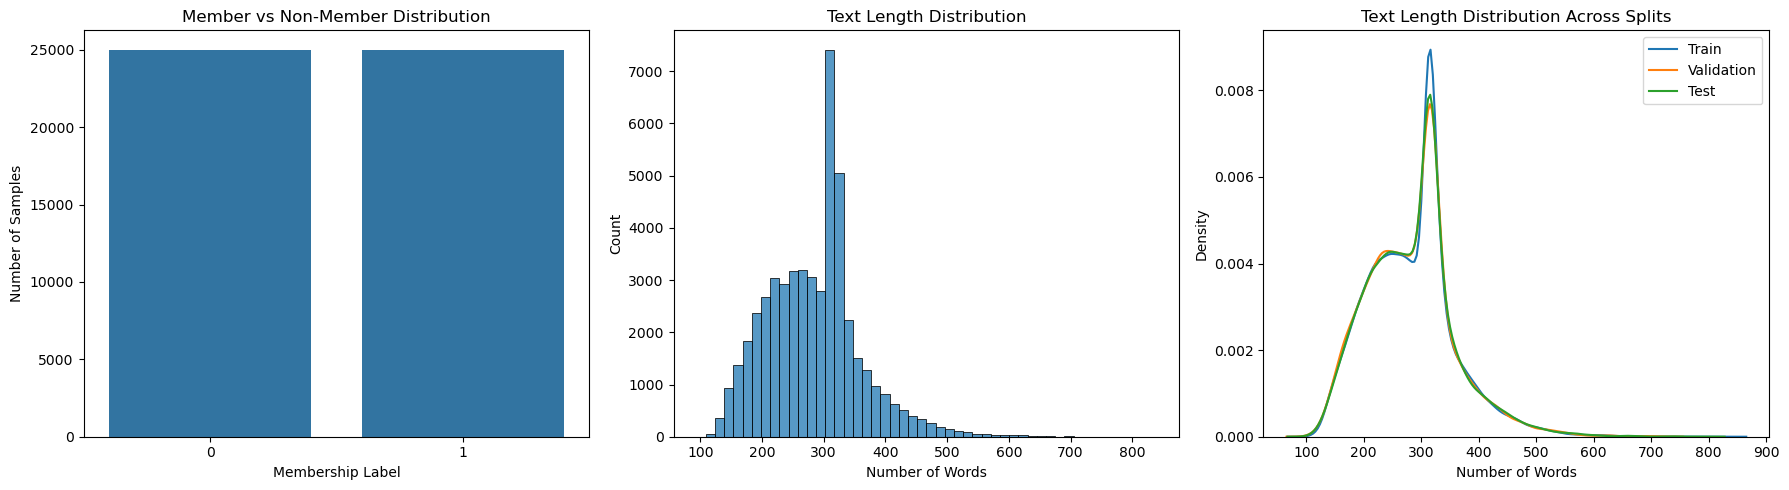

In [12]:
# convert train split to pandas
train_df = dataset["train"].to_pandas()

# compute text length
train_df["text_length"] = train_df["text"].apply(lambda x: len(str(x).split()))

# compute lengths for all splits
train_len = [len(str(x).split()) for x in dataset["train"]["text"]]
val_len = [len(str(x).split()) for x in dataset["validation"]["text"]]
test_len = [len(str(x).split()) for x in dataset["test"]["text"]]

plt.figure(figsize=(18,5))

# 1 Member vs Non-member
plt.subplot(1,3,1)
sns.countplot(x="is_member", data=train_df)
plt.title("Member vs Non-Member Distribution")
plt.xlabel("Membership Label")
plt.ylabel("Number of Samples")

# 2 Text length distribution
plt.subplot(1,3,2)
sns.histplot(train_df["text_length"], bins=50)
plt.title("Text Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Count")

# 3 Train vs Validation vs Test comparison
plt.subplot(1,3,3)
sns.kdeplot(train_len, label="Train")
sns.kdeplot(val_len, label="Validation")
sns.kdeplot(test_len, label="Test")
plt.title("Text Length Distribution Across Splits")
plt.xlabel("Number of Words")
plt.legend()

plt.tight_layout()
plt.show()